# Loan Approved Dataset

Step 0 - Importing Libraries :

In [1]:
pip install seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
pip install matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)


**Step 1 - Data Collection**

In [4]:
data = pd.read_csv(r"C:\Users\ganga\Downloads\loan_approval_dataset.csv")



In [5]:
df=data.copy()

In [6]:
df.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP1000,Male,No,0,Graduate,No,11298,0,700.0,360.0,0.0,Urban,N
1,LP1001,Female,Yes,0,Graduate,No,7951,5473,700.0,360.0,1.0,Semiurban,N
2,LP1002,Male,Yes,0,Graduate,No,5992,2865,700.0,360.0,1.0,Rural,N
3,LP1003,Male,Yes,0,Graduate,No,5485,2561,700.0,360.0,1.0,Semiurban,N
4,LP1004,Male,Yes,0,Graduate,No,6148,6136,700.0,360.0,1.0,Urban,N


Step 2 - EDA (Data Understanding)

In [7]:
df.shape

(800, 13)

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            800 non-null    str    
 1   Gender             784 non-null    str    
 2   Married            792 non-null    str    
 3   Dependents         776 non-null    str    
 4   Education          800 non-null    str    
 5   Self_Employed      760 non-null    str    
 6   ApplicantIncome    800 non-null    int64  
 7   CoapplicantIncome  800 non-null    int64  
 8   LoanAmount         776 non-null    float64
 9   Loan_Amount_Term   784 non-null    float64
 10  Credit_History     736 non-null    float64
 11  Property_Area      800 non-null    str    
 12  Loan_Status        800 non-null    str    
dtypes: float64(3), int64(2), str(8)
memory usage: 107.0 KB


In [9]:
df.describe()

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,800.000000,800.000000,776.000000,784.000000,736.000000
mean,7546.548750,1547.350000,681.487113,324.719388,0.828804
std,2682.173432,1561.745445,60.092272,87.832843,0.376936
min,2361.000000,0.000000,309.000000,120.000000,0.000000
25%,5620.000000,0.000000,700.000000,300.000000,1.000000
50%,7222.000000,1386.000000,700.000000,360.000000,1.000000
75%,9130.250000,2422.500000,700.000000,360.000000,1.000000
max,20415.000000,8358.000000,700.000000,480.000000,1.000000


In [10]:
df.describe(include=['O'])

C:\Users\ganga\AppData\Local\Temp\ipykernel_5868\69473401.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include=['O'])


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,Property_Area,Loan_Status
count,800,784,792,776,800,760,800,800
unique,800,2,2,4,2,2,3,2
top,LP1000,Male,Yes,0,Graduate,No,Urban,Y
freq,1,606,504,424,622,660,320,414


In [11]:
#checking null values

df.isnull().sum()

Loan_ID               0
Gender               16
Married               8
Dependents           24
Education             0
Self_Employed        40
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           24
Loan_Amount_Term     16
Credit_History       64
Property_Area         0
Loan_Status           0
dtype: int64

In [12]:
df["Gender"].fillna(df["Gender"].mode()[0], inplace=True)
df["Married"].fillna(df["Married"].mode()[0], inplace=True)
df["Dependents"].fillna(df["Dependents"].mode()[0], inplace=True)
df["Self_Employed"].fillna(df["Self_Employed"].mode()[0], inplace=True)
df["Credit_History"].fillna(df["Credit_History"].mode()[0], inplace=True)

C:\Users\ganga\AppData\Local\Temp\ipykernel_5868\3629185675.py:1: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df["Gender"].fillna(df["Gender"].mode()[0], inplace=True)
C:\Users\ganga\AppData\Local\Temp\ipykernel_5868\3629185675.py:2: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained ass

0      0.0
1      1.0
2      1.0
3      1.0
4      1.0
      ... 
795    0.0
796    0.0
797    1.0
798    1.0
799    1.0
Name: Credit_History, Length: 800, dtype: float64

In [13]:
df["LoanAmount"].fillna(df["LoanAmount"].median(), inplace=True)
df["Loan_Amount_Term"].fillna(df["Loan_Amount_Term"].median(), inplace=True)

C:\Users\ganga\AppData\Local\Temp\ipykernel_5868\1965199118.py:1: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df["LoanAmount"].fillna(df["LoanAmount"].median(), inplace=True)
C:\Users\ganga\AppData\Local\Temp\ipykernel_5868\1965199118.py:2: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chai

0      360.0
1      360.0
2      360.0
3      360.0
4      360.0
       ...  
795    480.0
796    300.0
797    180.0
798    360.0
799    180.0
Name: Loan_Amount_Term, Length: 800, dtype: float64

In [14]:
df.isnull().sum().sum()

np.int64(192)

In [15]:
# percentage of null values
print((df.isnull().sum().sum()/len(df))*100)

24.0


In [16]:
print (df.columns)

Index(['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education',
       'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'Loan_Status'],
      dtype='str')


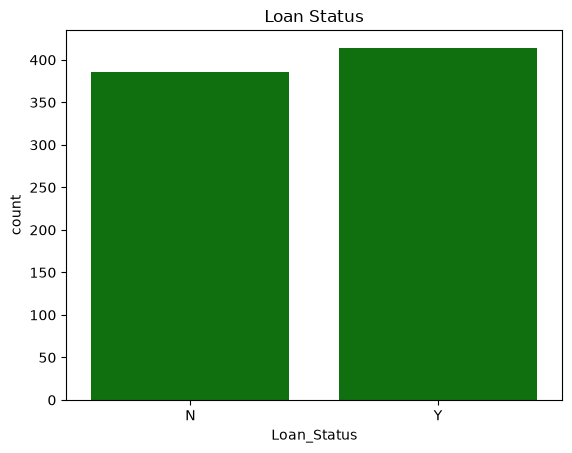

In [17]:
#Checking Target Distribution

sns.countplot(data=df, x='Loan_Status',color='green')
plt.title("Loan Status")
plt.show()

In [18]:
# Numerical and Categorical Columns

num_cols = df.select_dtypes(include=['int64', 'float64']).columns
cat_cols = df.select_dtypes(include=['object']).columns

C:\Users\ganga\AppData\Local\Temp\ipykernel_5868\79145757.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include=['object']).columns


In [19]:
print(num_cols)

Index(['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History'],
      dtype='str')


In [20]:
print(cat_cols)

Index(['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education',
       'Self_Employed', 'Property_Area', 'Loan_Status'],
      dtype='str')


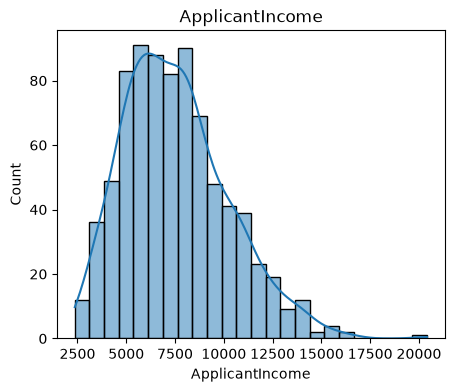

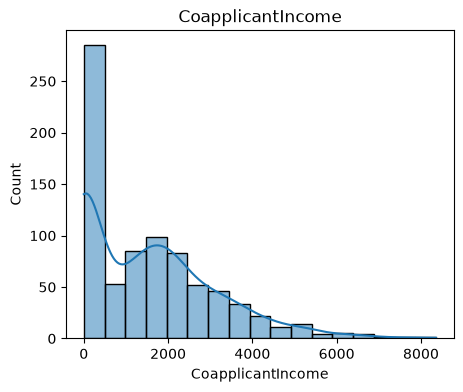

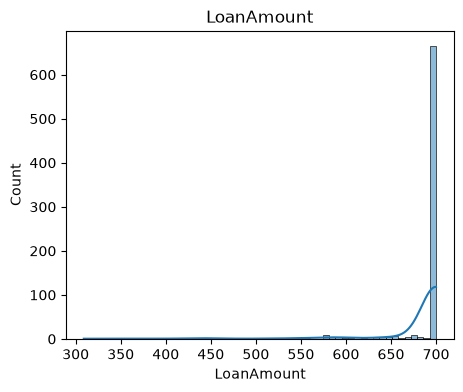

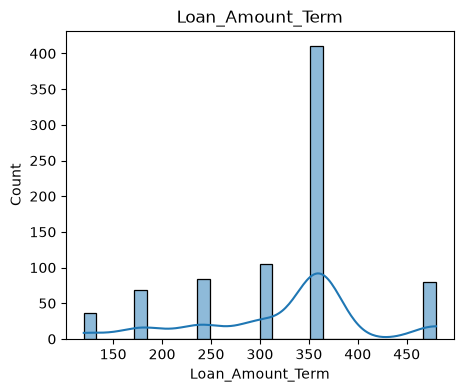

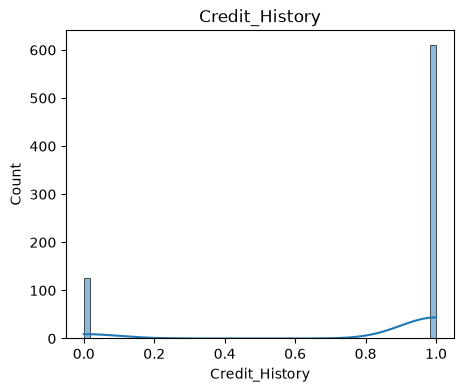

In [21]:
#Uni Variate Analysis

for col in num_cols:
    plt.figure(figsize=(5,4))
    sns.histplot(df[col], kde=True)
    plt.title(col)
    plt.show()



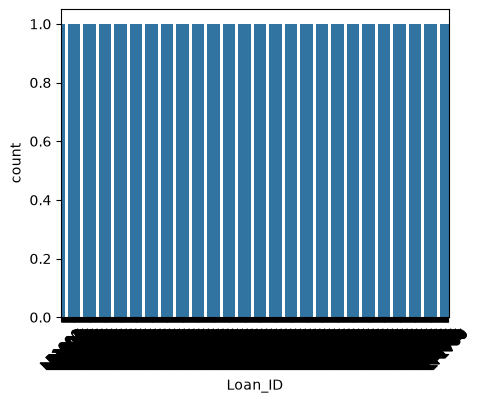

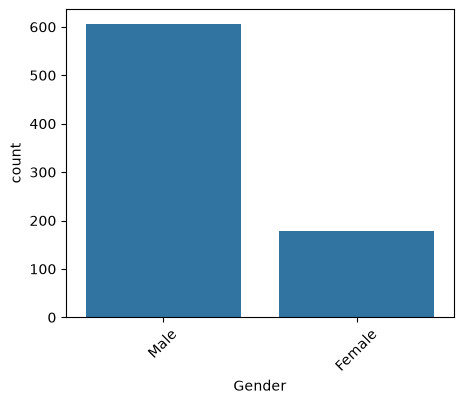

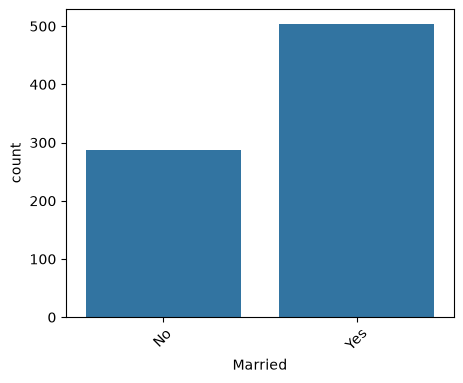

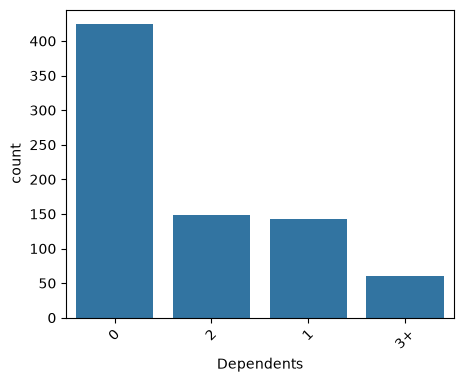

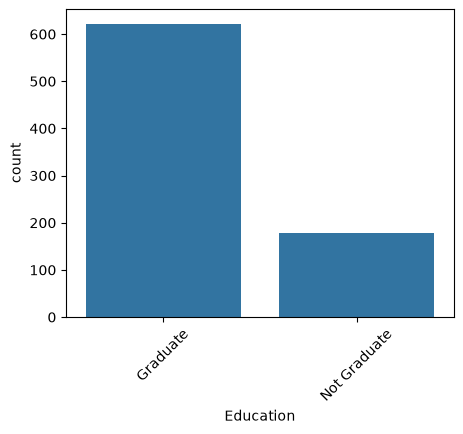

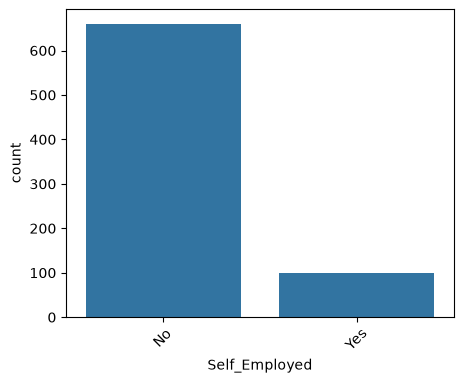

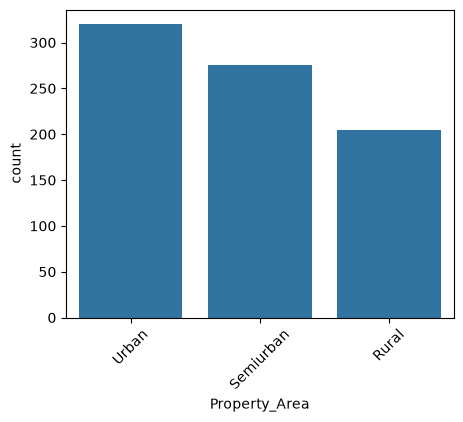

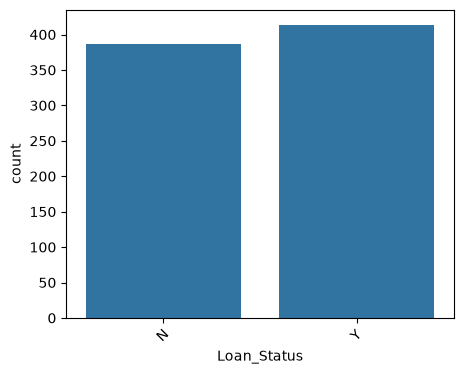

In [22]:
for col in cat_cols:
    plt.figure(figsize=(5,4))
    sns.countplot(data=df, x=col)
    plt.xticks(rotation=45)
    plt.show()

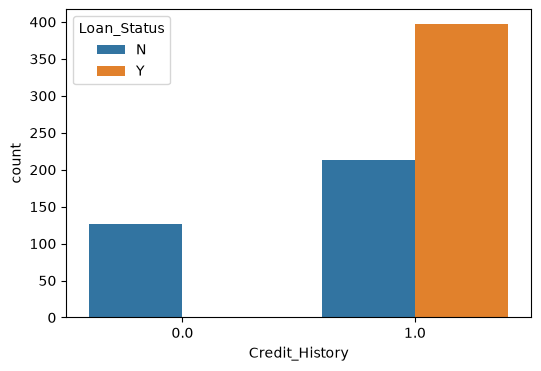

In [23]:
# Bivariate Analysis
plt.figure(figsize=(6,4))
sns.countplot(data=df, x='Credit_History', hue='Loan_Status')
plt.show()

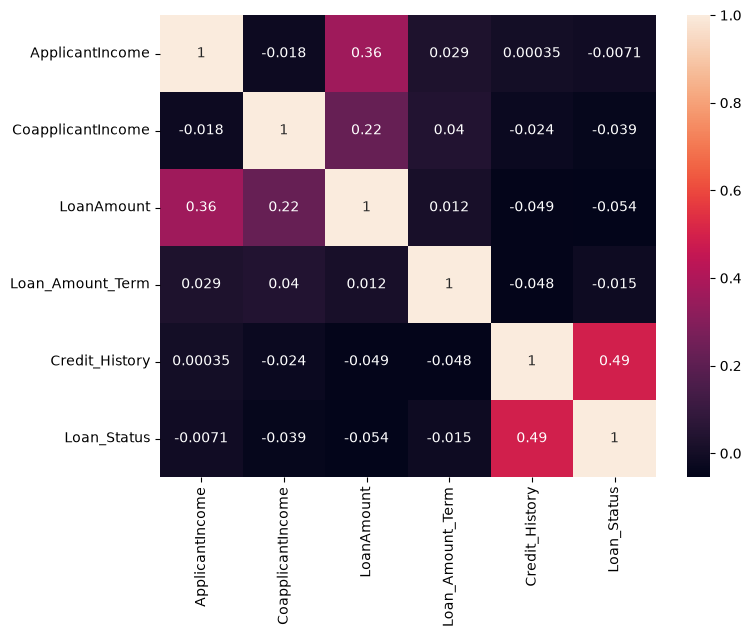

In [24]:
# Correlation
df['Loan_Status'] = df['Loan_Status'].map({'N':0,'Y':1})
plt.figure(figsize=(8,6))
sns.heatmap(df.corr(numeric_only=True), annot=True)
plt.show()


**Step 3 : Feature Engineering**

In [25]:
# Feature Engineering

df['Dependents'] = df['Dependents'].replace('3+','3')


In [26]:
type(df['Dependents'])

pandas.Series

In [27]:
df['Dependents'] = pd.to_numeric(df['Dependents'])



In [28]:
type(df['Dependents'])

pandas.Series

In [29]:
df['TotalIncome'] = df['ApplicantIncome'] + df['CoapplicantIncome']
df['EMI'] = (df['LoanAmount']*1000)/360
df['Income_Per_Person'] = df['TotalIncome']/(df['Dependents']+1)

if 'Loan_ID' in df.columns:
    df.drop('Loan_ID', axis=1, inplace=True)

**Step 4 : X and y**

In [30]:
X = df.drop('Loan_Status', axis=1)
y = df['Loan_Status']


In [31]:
y

0      0
1      0
2      0
3      0
4      0
      ..
795    0
796    0
797    0
798    1
799    1
Name: Loan_Status, Length: 800, dtype: int64

In [32]:
X

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,TotalIncome,EMI,Income_Per_Person
0,Male,No,0.0,Graduate,No,11298,0,700.0,360.0,0.0,Urban,11298,1944.444444,11298.0
1,Female,Yes,0.0,Graduate,No,7951,5473,700.0,360.0,1.0,Semiurban,13424,1944.444444,13424.0
2,Male,Yes,0.0,Graduate,No,5992,2865,700.0,360.0,1.0,Rural,8857,1944.444444,8857.0
3,Male,Yes,0.0,Graduate,No,5485,2561,700.0,360.0,1.0,Semiurban,8046,1944.444444,8046.0
4,Male,Yes,0.0,Graduate,No,6148,6136,700.0,360.0,1.0,Urban,12284,1944.444444,12284.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
795,Female,Yes,0.0,Graduate,No,7660,1497,700.0,480.0,0.0,Urban,9157,1944.444444,9157.0
796,Female,Yes,NaN,Not Graduate,No,4915,5495,700.0,300.0,0.0,Rural,10410,1944.444444,NaN
797,Male,Yes,0.0,Not Graduate,No,6626,867,700.0,180.0,1.0,Rural,7493,1944.444444,7493.0
798,Male,Yes,1.0,Graduate,No,10797,0,700.0,360.0,1.0,Rural,10797,1944.444444,5398.5


**Step 5 : Train-Test-Split**

In [33]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

**Step 6 : Preprocessing Pipeline**

In [34]:
num_features = X_train.select_dtypes(include=['int64','float64']).columns
cat_features = X_train.select_dtypes(include=['object']).columns


C:\Users\ganga\AppData\Local\Temp\ipykernel_5868\2146808463.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_features = X_train.select_dtypes(include=['object']).columns


In [35]:
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

In [36]:
cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore',sparse_output=False))
])

In [37]:
preprocessor = ColumnTransformer([
    ('num', num_pipeline, num_features),
    ('cat', cat_pipeline, cat_features)
])

**Step 7 : Baseline Models**

In [38]:
models = {"KNN": KNeighborsClassifier(),
    "Naive Bayes": GaussianNB()
}

for name, model in models.items():

    pipe = Pipeline([('preprocessor', preprocessor),('model', model)])

    pipe.fit(X_train, y_train)

    pred = pipe.predict(X_test)

    print(name)
    print("Accuracy:", accuracy_score(y_test, pred))
    print()

KNN
Accuracy: 0.69375

Naive Bayes
Accuracy: 0.6625



**Step 8 : Hyperparameter Tuning**

In [39]:
from sklearn.model_selection import train_test_split, GridSearchCV

knn_pipeline = Pipeline([('preprocessor', preprocessor),
    ('model', KNeighborsClassifier())
])

In [40]:
param_grid_knn = {
    'model__n_neighbors':[3,5,7,9,11,15],
    'model__weights':['uniform','distance'],
    'model__metric':['euclidean','manhattan']
}

In [41]:
grid_knn = GridSearchCV(
    knn_pipeline,param_grid_knn,cv=5,scoring='accuracy',n_jobs=-1)

In [42]:
grid_knn.fit(X_train,y_train)

print("Best KNN Parameters:")
print(grid_knn.best_params_)

print("Best KNN CV Score:")
print(grid_knn.best_score_)

Best KNN Parameters:
{'model__metric': 'euclidean', 'model__n_neighbors': 9, 'model__weights': 'uniform'}
Best KNN CV Score:
0.7109375


In [43]:
# HP Tuning for NB

nb_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', GaussianNB())])

In [44]:
param_grid_nb = {
    'model__var_smoothing':np.logspace(0,-9,100)
}

In [45]:
grid_nb = GridSearchCV(
    nb_pipeline,
    param_grid_nb,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

In [46]:
grid_nb.fit(X_train,y_train)

print("Best NB Parameters:")
print(grid_nb.best_params_)

print("Best NB CV Score:")
print(grid_nb.best_score_)

Best NB Parameters:
{'model__var_smoothing': np.float64(0.0533669923120631)}
Best NB CV Score:
0.7265625


**Step 9 : Model Evaluation**

In [47]:
#KNN

best_knn = grid_knn.best_estimator_

In [48]:
knn_pred = best_knn.predict(X_test)

In [49]:
print("KNN Accuracy:")
print(accuracy_score(y_test,knn_pred))

KNN Accuracy:
0.7125


In [50]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

print(classification_report(y_test,knn_pred))

              precision    recall  f1-score   support

           0       0.77      0.57      0.66        77
           1       0.68      0.84      0.75        83

    accuracy                           0.71       160
   macro avg       0.73      0.71      0.70       160
weighted avg       0.72      0.71      0.71       160



In [51]:
print(confusion_matrix(y_test,knn_pred))

[[44 33]
 [13 70]]


In [52]:
knn_prob = best_knn.predict_proba(X_test)[:,1] #predicts probability of each class for all samples , especially giving second column,helpful for roc auc

In [53]:
print("KNN ROC-AUC:")
print(roc_auc_score(y_test,knn_prob))

KNN ROC-AUC:
0.7740572680331717


In [54]:
# Naive Baye's

best_nb = grid_nb.best_estimator_

In [55]:
nb_pred = best_nb.predict(X_test)

In [56]:
print("NB Accuracy:")
print(accuracy_score(y_test,nb_pred))


NB Accuracy:
0.74375


In [57]:
print(classification_report(y_test,nb_pred))

              precision    recall  f1-score   support

           0       0.91      0.52      0.66        77
           1       0.68      0.95      0.79        83

    accuracy                           0.74       160
   macro avg       0.80      0.74      0.73       160
weighted avg       0.79      0.74      0.73       160



In [58]:
print(confusion_matrix(y_test,nb_pred))



[[40 37]
 [ 4 79]]


In [59]:
nb_prob = best_nb.predict_proba(X_test)[:,1]



In [60]:
nb_prob

array([9.12959411e-01, 3.91397916e-01, 3.56140048e-30, 7.79476288e-01,
       9.67415161e-01, 9.86698670e-01, 9.76972854e-01, 1.40893079e-01,
       4.63383958e-29, 9.79029132e-01, 1.40929867e-29, 3.97579966e-29,
       9.73066707e-01, 9.65532910e-01, 9.23664352e-01, 9.20967618e-01,
       9.44178665e-01, 8.79438077e-01, 3.19191230e-01, 9.82436161e-01,
       8.58004155e-01, 8.83358463e-01, 9.61133867e-01, 9.26922807e-01,
       9.03783234e-01, 9.81436750e-01, 7.60418394e-29, 1.15949884e-29,
       7.92986512e-01, 9.65586114e-01, 2.00868968e-01, 9.32244520e-01,
       9.10227705e-01, 2.17285395e-01, 1.33883924e-01, 1.04344417e-30,
       8.43541282e-01, 1.94940358e-01, 9.85402752e-01, 9.87788640e-01,
       6.15093530e-01, 9.99005031e-01, 2.77061884e-01, 9.28407168e-01,
       9.33424623e-01, 2.10911723e-01, 8.60039852e-01, 9.65349521e-01,
       9.10971583e-01, 9.90895837e-01, 8.52167874e-01, 8.51071092e-01,
       2.28180861e-01, 1.22307556e-01, 9.82028247e-01, 9.37019192e-01,
      

In [61]:
print("NB ROC-AUC:")
print(roc_auc_score(y_test,nb_prob))

NB ROC-AUC:
0.8272570802691285


 **Step 10 : Best Model Selection**

In [62]:
knn_acc = accuracy_score(
    y_test,
    best_knn.predict(X_test)
)

In [63]:
knn_acc

0.7125

In [64]:
nb_acc = accuracy_score(
    y_test,
    best_nb.predict(X_test)
)

In [65]:
nb_acc

0.74375

In [66]:
if knn_acc > nb_acc:
    best_model = best_knn
    print("Best Model = KNN")
else:
    best_model = best_nb
    print("Best Model = Naive Bayes")

Best Model = Naive Bayes


**Step 11 : Save Complete Pipeline**

In [67]:
import joblib

joblib.dump(best_model,"loan_pipeline.pkl")

['loan_pipeline.pkl']

**Step 12 : Deployment(Streamlit Template)**

In [68]:
!pip install streamlit


[notice] A new release of pip is available: 25.2 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [69]:
import streamlit as st
import joblib

model = joblib.load("loan_pipeline.pkl")



In [70]:
model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](14,)","['Gender','Married','Dependents',...,'TotalIncome','EMI', 'Income_Per_Person']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,14
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'`

In [71]:
'''
Refer Streamlit Deployment Discussion as a continuation

st.title("Loan Approval Prediction")

'''

'\nRefer Streamlit Deployment Discussion as a continuation\n\nst.title("Loan Approval Prediction")\n\n'